In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/online_retail_II.csv", encoding="latin-1")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("Raw rows:", len(df))

n = len(df)
df = df.drop_duplicates()
print("Duplicates removed:", n - len(df))

n = len(df)
df = df[~df["Invoice"].astype(str).str.startswith("C")]
print("Cancellations removed:", n - len(df))

n = len(df)
df = df[df["Price"] > 0]
print("Price <= 0 removed:", n - len(df))

n = len(df)
df = df[df["Quantity"] > 0]
print("Quantity <= 0 removed:", n - len(df))

print("Rows after cleaning:", len(df))

Raw rows: 1067371
Duplicates removed: 34335
Cancellations removed: 19104
Price <= 0 removed: 6019
Quantity <= 0 removed: 0
Rows after cleaning: 1007913


In [18]:
df["Revenue"] = df["Quantity"] * df["Price"]
print(df["Revenue"].describe())

count    1.007913e+06
mean     2.031550e+01
std      2.057158e+02
min      1.000000e-03
25%      4.130000e+00
50%      1.008000e+01
75%      1.770000e+01
max      1.684696e+05
Name: Revenue, dtype: float64


In [19]:
non_product_mask = ~df["StockCode"].astype(str).str.match(r"^\d")
print("Rows with non-product codes:", non_product_mask.sum())
df[non_product_mask]["StockCode"].value_counts()

Rows with non-product codes: 4699


StockCode
POST            1851
DOT             1415
M                846
C2               267
ADJUST            36
BANK CHARGES      34
DCGS0058          30
gift_0001_20      26
gift_0001_30      24
DCGSSGIRL         23
DCGSSBOY          21
PADS              17
DCGS0076          14
gift_0001_10      14
DCGS0003          13
TEST001            9
gift_0001_50       6
m                  5
DCGS0069           5
D                  5
gift_0001_40       5
DCGS0004           4
DCGS0072           3
S                  3
ADJUST2            3
AMAZONFEE          3
DCGS0068           2
DCGS0066N          2
DCGS0070           2
SP1002             2
gift_0001_80       1
DCGS0044           1
TEST002            1
DCGS0075           1
DCGS0041           1
gift_0001_70       1
DCGS0037           1
DCGS0062           1
B                  1
Name: count, dtype: int64

In [20]:
n = len(df)
df_sales = df[~non_product_mask].copy()
print("Non-product rows removed:", n - len(df_sales))

df_customers = df_sales.dropna(subset=["Customer ID"]).copy()
df_customers["Customer ID"] = df_customers["Customer ID"].astype(int)

print("df_sales shape:", df_sales.shape)
print("df_customers shape:", df_customers.shape)
print("Unique customers:", df_customers["Customer ID"].nunique())

Non-product rows removed: 4699
df_sales shape: (1003214, 9)
df_customers shape: (776577, 9)
Unique customers: 5852


In [21]:
df_sales.to_csv("../data/processed/sales_clean.csv", index=False)
df_customers.to_csv("../data/processed/customers_clean.csv", index=False)
print("Saved")

Saved


In [22]:
snapshot_date = df_customers["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df_customers.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
).reset_index()

print(rfm.shape)
rfm.describe()

(5852, 4)


,Customer ID,Recency,Frequency,Monetary
count,5852.000000,5852.000000,5852.000000,5852.000000
mean,15319.707109,200.198052,6.253247,2916.706762
std,1714.929942,208.509570,12.749286,14306.854987
min,12346.000000,1.000000,1.000000,2.950000
25%,13837.750000,25.000000,1.000000,339.575000
50%,15320.500000,95.000000,3.000000,856.020000
75%,16802.250000,379.000000,7.000000,2241.030000
max,18287.000000,739.000000,373.000000,580987.040000


In [23]:
rfm["R_score"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F_score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M_score"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm.head()

,Customer ID,Recency,Frequency,Monetary,R_score,F_score,M_score
0,12346,326,3,77352.96,2,3,5
1,12347,2,8,4921.53,5,4,5
2,12348,75,5,1658.40,3,4,4
3,12349,19,3,3678.69,5,3,5
4,12350,310,1,294.40,2,1,2


In [24]:
daily = (
    df_sales.set_index("InvoiceDate")["Revenue"]
    .resample("D").sum()
    .to_frame("Revenue")
)

daily["roll_7"] = daily["Revenue"].rolling(7).mean()
daily["roll_30"] = daily["Revenue"].rolling(30).mean()

daily.tail()

,Revenue,roll_7,roll_30
InvoiceDate,,,
2011-12-05,80011.23,47851.462857,48827.251000
2011-12-06,55257.31,46017.020000,49264.033000
2011-12-07,72799.09,48404.304286,48885.669000
2011-12-08,77562.86,52255.875714,49650.500000
2011-12-09,198094.64,72566.942857,54091.483667


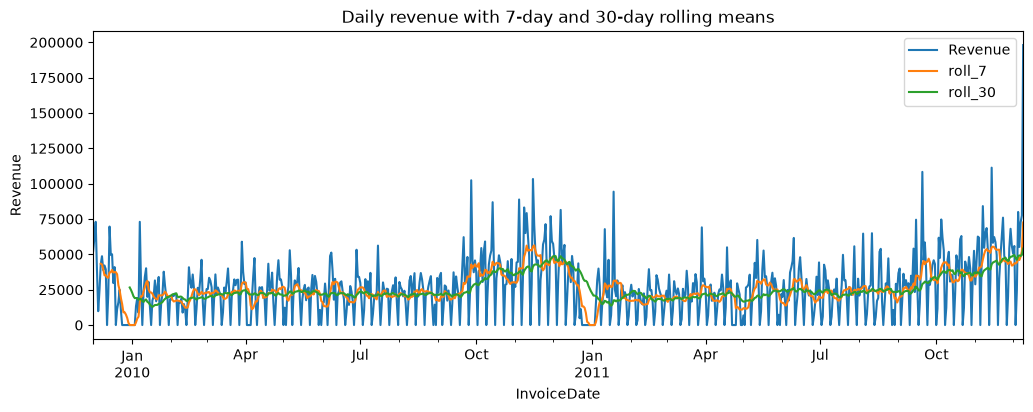

In [25]:
import matplotlib.pyplot as plt

daily[["Revenue", "roll_7", "roll_30"]].plot(figsize=(12, 4))
plt.title("Daily revenue with 7-day and 30-day rolling means")
plt.ylabel("Revenue")
plt.savefig("../reports/figures/04_daily_revenue_rolling.png", dpi=150, bbox_inches="tight")
plt.show()

In [26]:
rfm.to_csv("../data/processed/rfm.csv", index=False)
daily.to_csv("../data/processed/daily_sales.csv")

In [27]:
import great_expectations as gx
import great_expectations.expectations as gxe

def validate(df, expectations, name):
    """Run a list of expectations on a DataFrame and print PASS/FAIL for each."""
    context = gx.get_context()
    source = context.data_sources.add_pandas(f"{name}_source")
    asset = source.add_dataframe_asset(name=f"{name}_asset")
    batch_def = asset.add_batch_definition_whole_dataframe(f"{name}_batch")
    batch = batch_def.get_batch(batch_parameters={"dataframe": df})

    all_ok = True
    for exp in expectations:
        result = batch.validate(exp)
        status = "PASS" if result.success else "FAIL"
        all_ok = all_ok and result.success
        print(f"[{status}] {type(exp).__name__}: {exp.column if hasattr(exp, 'column') else ''}")
    print(f"\n{name}: {'ALL CHECKS PASSED' if all_ok else 'SOME CHECKS FAILED'}")
    return all_ok

In [28]:
sales_checks = [
    gxe.ExpectColumnValuesToNotBeNull(column="Invoice"),
    gxe.ExpectColumnValuesToNotBeNull(column="StockCode"),
    gxe.ExpectColumnValuesToNotBeNull(column="InvoiceDate"),
    gxe.ExpectColumnValuesToBeBetween(column="Price", min_value=0, strict_min=True),
    gxe.ExpectColumnValuesToBeBetween(column="Quantity", min_value=0, strict_min=True),
    gxe.ExpectColumnValuesToBeBetween(column="Revenue", min_value=0, strict_min=True),
]
validate(df_sales, sales_checks, "sales")

Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToNotBeNull: Invoice


Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToNotBeNull: StockCode


Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

...

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeBetween: Quantity


Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeBetween: Revenue

sales: ALL CHECKS PASSED


True

In [29]:
customer_checks = [
    gxe.ExpectColumnValuesToNotBeNull(column="Customer ID"),
    gxe.ExpectColumnValuesToBeBetween(column="Quantity", min_value=0, strict_min=True),
    gxe.ExpectColumnValuesToBeBetween(column="Price", min_value=0, strict_min=True),
]
validate(df_customers, customer_checks, "customers")

Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToNotBeNull: Customer ID


Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeBetween: Quantity


Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeBetween: Price

customers: ALL CHECKS PASSED


True

In [30]:
rfm_checks = [
    gxe.ExpectColumnValuesToBeUnique(column="Customer ID"),
    gxe.ExpectColumnValuesToBeBetween(column="Recency", min_value=0),
    gxe.ExpectColumnValuesToBeBetween(column="Frequency", min_value=1),
    gxe.ExpectColumnValuesToBeBetween(column="Monetary", min_value=0, strict_min=True),
]
validate(rfm, rfm_checks, "rfm")

Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeUnique: Customer ID


Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeBetween: Recency


Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeBetween: Frequency


Calculating Metrics:   0%|          | 0/10 [00:00<?, ?it/s]

[PASS] ExpectColumnValuesToBeBetween: Monetary

rfm: ALL CHECKS PASSED


True